# 2. Feature Engineering

**Proje:** Kredi Riski Skorlama ve Model Validasyonu
**Amaç:** Ham veriyi temizlemek, belgelenmemiş değerleri düzeltmek ve modelleme için türetilmiş değişkenler oluşturmak.

---

## 2.1 Kütüphaneler

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import duckdb

plt.rcParams['figure.figsize'] = (12, 6)
sns.set_style('whitegrid')
pd.set_option('display.max_columns', 40)

print("Kütüphaneler yüklendi.")

Kütüphaneler yüklendi.


## 2.2 Veri Yükleme

In [2]:
df = pd.read_csv('../data/credit_default.csv')
print(f"Orijinal veri: {df.shape[0]:,} satır, {df.shape[1]} sütun")
df.head()

Orijinal veri: 30,000 satır, 25 sütun


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
0,1,20000,2,2,1,24,2,2,-1,-1,-2,-2,3913,3102,689,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,0,2,2682,1725,2682,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,0,0,29239,14027,13559,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,4,50000,2,2,1,37,0,0,0,0,0,0,46990,48233,49291,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,5,50000,1,2,1,57,-1,0,-1,0,0,0,8617,5670,35835,20940,19146,19131,2000,36681,10000,9000,689,679,0


## 2.3 Hedef Değişken Yeniden Adlandırma

Orijinal hedef değişken adı uzun ve kullanışsız. Daha profesyonel bir isimlendirme yapıyoruz.

In [3]:
df = df.rename(columns={'default payment next month': 'DEFAULT_FLAG'})

# ID sütununu index olarak sakla ama modellemeye dahil etme
df = df.set_index('ID')
print(f"Değişkenler: {list(df.columns)}")
print(f"Shape: {df.shape}")

Değişkenler: ['LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE', 'PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6', 'DEFAULT_FLAG']
Shape: (30000, 24)


## 2.4 Veri Temizleme

### 2.4.1 EDUCATION Değişkeni
Belgelemedeki değerler: 1=Lisansüstü, 2=Üniversite, 3=Lise, 4=Diğer.
Veride 0, 5, 6 gibi belgelenmemiş değerler var → hepsini "4=Diğer" olarak birleştiriyoruz.

In [4]:
print("EDUCATION - Temizleme öncesi:")
print(df['EDUCATION'].value_counts().sort_index())

# 0, 5, 6 → 4 (Diğer)
df['EDUCATION'] = df['EDUCATION'].replace({0: 4, 5: 4, 6: 4})

print("\nEDUCATION - Temizleme sonrası:")
print(df['EDUCATION'].value_counts().sort_index())

EDUCATION - Temizleme öncesi:
EDUCATION
0       14
1    10585
2    14030
3     4917
4      123
5      280
6       51
Name: count, dtype: int64

EDUCATION - Temizleme sonrası:
EDUCATION
1    10585
2    14030
3     4917
4      468
Name: count, dtype: int64


### 2.4.2 MARRIAGE Değişkeni
Belgelemedeki değerler: 1=Evli, 2=Bekar, 3=Diğer.
Veride 0 değeri var → "3=Diğer" olarak birleştiriyoruz.

In [5]:
print("MARRIAGE - Temizleme öncesi:")
print(df['MARRIAGE'].value_counts().sort_index())

df['MARRIAGE'] = df['MARRIAGE'].replace({0: 3})

print("\nMARRIAGE - Temizleme sonrası:")
print(df['MARRIAGE'].value_counts().sort_index())

MARRIAGE - Temizleme öncesi:
MARRIAGE
0       54
1    13659
2    15964
3      323
Name: count, dtype: int64

MARRIAGE - Temizleme sonrası:
MARRIAGE
1    13659
2    15964
3      377
Name: count, dtype: int64


## 2.5 Türetilmiş Değişkenler

Kredi riski modellemesinde en güçlü sinyaller genellikle:
- Ödeme geçmişi davranışları
- Limit kullanım oranları
- Ödeme/ekstre oranları

olarak bilinir. Bu iş bilgisine dayanarak yeni değişkenler türetiyoruz.

### 2.5.1 Ödeme Gecikme Türevleri

In [6]:
pay_cols = ['PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6']

# Son 6 aydaki maksimum gecikme
df['MAX_DELINQUENCY'] = df[pay_cols].max(axis=1)

# Son 6 aydaki ortalama gecikme
df['AVG_DELINQUENCY'] = df[pay_cols].mean(axis=1).round(4)

# Gecikme yaşanan ay sayısı (PAY > 0 olan aylar)
df['DELINQUENCY_COUNT'] = (df[pay_cols] > 0).sum(axis=1)

# Hiç gecikme yaşamamış mı? (tüm PAY <= 0)
df['NEVER_DELINQUENT'] = (df[pay_cols].max(axis=1) <= 0).astype(int)

# Son aydaki gecikme seviyesi (PAY_0'ın ikili hali)
df['RECENT_DELINQUENT'] = (df['PAY_0'] > 0).astype(int)

print("Gecikme türevleri oluşturuldu:")
print(df[['MAX_DELINQUENCY', 'AVG_DELINQUENCY', 'DELINQUENCY_COUNT',
          'NEVER_DELINQUENT', 'RECENT_DELINQUENT']].describe().round(3))

Gecikme türevleri oluşturuldu:
       MAX_DELINQUENCY  AVG_DELINQUENCY  DELINQUENCY_COUNT  NEVER_DELINQUENT  \
count        30000.000        30000.000          30000.000         30000.000   
mean             0.439           -0.182              0.834             0.664   
std              1.345            0.982              1.554             0.472   
min             -2.000           -2.000              0.000             0.000   
25%              0.000           -0.833              0.000             0.000   
50%              0.000            0.000              0.000             1.000   
75%              2.000            0.000              1.000             1.000   
max              8.000            6.000              6.000             1.000   

       RECENT_DELINQUENT  
count          30000.000  
mean               0.227  
std                0.419  
min                0.000  
25%                0.000  
50%                0.000  
75%                0.000  
max                1.000  


### 2.5.2 Ekstre ve Ödeme Türevleri

In [7]:
bill_cols = ['BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6']
pay_amt_cols = ['PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6']

# Toplam ekstre tutarı (son 6 ay)
df['TOTAL_BILL'] = df[bill_cols].sum(axis=1)

# Toplam ödeme tutarı (son 6 ay)
df['TOTAL_PAY'] = df[pay_amt_cols].sum(axis=1)

# Ödeme / Ekstre oranı (toplam)
# Sıfıra bölme koruması: ekstre 0 veya negatifse oran 1.0 kabul edilir
df['PAY_TO_BILL_RATIO'] = np.where(
    df['TOTAL_BILL'] > 0,
    (df['TOTAL_PAY'] / df['TOTAL_BILL']).clip(upper=5.0),
    1.0
)

# Son aydaki ödeme / ekstre oranı
df['RECENT_PAY_RATIO'] = np.where(
    df['BILL_AMT1'] > 0,
    (df['PAY_AMT1'] / df['BILL_AMT1']).clip(upper=5.0),
    1.0
)

# Ortalama aylık ekstre
df['AVG_BILL'] = df[bill_cols].mean(axis=1)

# Ortalama aylık ödeme
df['AVG_PAY'] = df[pay_amt_cols].mean(axis=1)

print("Ekstre/Ödeme türevleri oluşturuldu:")
print(df[['TOTAL_BILL', 'TOTAL_PAY', 'PAY_TO_BILL_RATIO',
          'RECENT_PAY_RATIO', 'AVG_BILL', 'AVG_PAY']].describe().round(2))

Ekstre/Ödeme türevleri oluşturuldu:
       TOTAL_BILL   TOTAL_PAY  PAY_TO_BILL_RATIO  RECENT_PAY_RATIO   AVG_BILL  \
count    30000.00    30000.00           30000.00          30000.00   30000.00   
mean    269861.67    31651.39               0.41              0.51   44976.95   
std     379564.33    60827.68               0.60              1.01   63260.72   
min    -336259.00        0.00               0.00              0.00  -56043.17   
25%      28688.00     6679.75               0.04              0.04    4781.33   
50%     126311.00    14383.00               0.11              0.07   21051.83   
75%     342626.50    33503.50               0.72              0.64   57104.42   
max    5263883.00  3764066.00               5.00              5.00  877313.83   

         AVG_PAY  
count   30000.00  
mean     5275.23  
std     10137.95  
min         0.00  
25%      1113.29  
50%      2397.17  
75%      5583.92  
max    627344.33  


### 2.5.3 Limit Kullanım Türevleri

In [8]:
# Limit kullanım oranı (en son ekstre / limit)
df['UTIL_RATIO'] = np.where(
    df['LIMIT_BAL'] > 0,
    (df['BILL_AMT1'] / df['LIMIT_BAL']).clip(-1, 2),
    0
)

# Ortalama limit kullanım oranı (6 ay ortalaması / limit)
df['AVG_UTIL_RATIO'] = np.where(
    df['LIMIT_BAL'] > 0,
    (df[bill_cols].mean(axis=1) / df['LIMIT_BAL']).clip(-1, 2),
    0
)

# Limit bandı (kategorik)
df['LIMIT_BAND'] = pd.cut(
    df['LIMIT_BAL'],
    bins=[0, 50000, 100000, 200000, 500000, float('inf')],
    labels=['Very Low', 'Low', 'Medium', 'High', 'Very High']
)

print("Limit kullanım türevleri oluşturuldu:")
print(df[['UTIL_RATIO', 'AVG_UTIL_RATIO']].describe().round(4))
print("\nLimit bandı dağılımı:")
print(df['LIMIT_BAND'].value_counts().sort_index())

Limit kullanım türevleri oluşturuldu:
       UTIL_RATIO  AVG_UTIL_RATIO
count  30000.0000      30000.0000
mean       0.4227          0.3728
std        0.4048          0.3498
min       -0.6199         -0.2326
25%        0.0220          0.0300
50%        0.3140          0.2848
75%        0.8298          0.6879
max        2.0000          2.0000

Limit bandı dağılımı:
LIMIT_BAND
Very Low     7676
Low          4822
Medium       7880
High         9416
Very High     206
Name: count, dtype: int64


### 2.5.4 Demografik Türevler

In [9]:
# Yaş bandı
df['AGE_BAND'] = pd.cut(
    df['AGE'],
    bins=[20, 25, 30, 35, 40, 50, 80],
    labels=['20-24', '25-29', '30-34', '35-39', '40-49', '50+'],
    right=False
)

print("Yaş bandı dağılımı:")
print(df['AGE_BAND'].value_counts().sort_index())

Yaş bandı dağılımı:
AGE_BAND
20-24    2685
25-29    6933
30-34    6078
35-39    5160
40-49    6464
50+      2680
Name: count, dtype: int64


### 2.5.5 Trend Değişkenleri

In [10]:
# Ekstre tutarı trendi: son 3 ay ortalaması - önceki 3 ay ortalaması
df['BILL_TREND'] = (
    df[['BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3']].mean(axis=1) -
    df[['BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6']].mean(axis=1)
)

# Ödeme tutarı trendi
df['PAY_TREND'] = (
    df[['PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3']].mean(axis=1) -
    df[['PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6']].mean(axis=1)
)

# Gecikme trendi (son 3 ay ort - önceki 3 ay ort)
df['DELINQUENCY_TREND'] = (
    df[['PAY_0', 'PAY_2', 'PAY_3']].mean(axis=1) -
    df[['PAY_4', 'PAY_5', 'PAY_6']].mean(axis=1)
)

print("Trend değişkenleri:")
print(df[['BILL_TREND', 'PAY_TREND', 'DELINQUENCY_TREND']].describe().round(2))

Trend değişkenleri:
       BILL_TREND  PAY_TREND  DELINQUENCY_TREND
count    30000.00   30000.00           30000.00
mean      8323.15     656.49               0.15
std      29831.16   13892.58               0.75
min    -291275.00 -177931.33              -5.33
25%      -1899.75    -316.67               0.00
50%        658.67     403.33               0.00
75%      12647.33    1513.08               0.33
max     432428.33  730688.67               4.33


## 2.6 Türetilmiş Değişken Analizi

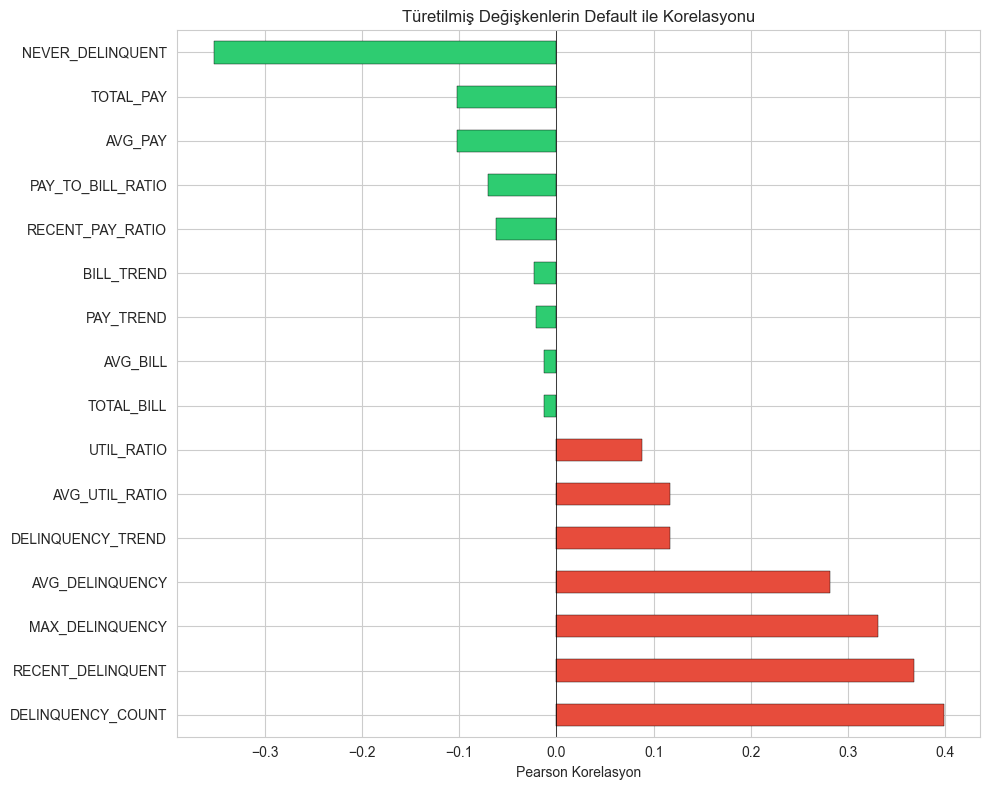


En güçlü korelasyonlar:
DELINQUENCY_COUNT    0.398394
RECENT_DELINQUENT    0.368117
MAX_DELINQUENCY      0.331036
AVG_DELINQUENCY      0.281955
DELINQUENCY_TREND    0.117062

En zayıf korelasyonlar:
RECENT_PAY_RATIO    -0.062626
PAY_TO_BILL_RATIO   -0.070075
AVG_PAY             -0.102354
TOTAL_PAY           -0.102354
NEVER_DELINQUENT    -0.352858


In [11]:
# Yeni değişkenlerin default ile korelasyonu
new_features = [
    'MAX_DELINQUENCY', 'AVG_DELINQUENCY', 'DELINQUENCY_COUNT',
    'NEVER_DELINQUENT', 'RECENT_DELINQUENT',
    'TOTAL_BILL', 'TOTAL_PAY', 'PAY_TO_BILL_RATIO', 'RECENT_PAY_RATIO',
    'AVG_BILL', 'AVG_PAY',
    'UTIL_RATIO', 'AVG_UTIL_RATIO',
    'BILL_TREND', 'PAY_TREND', 'DELINQUENCY_TREND'
]

corr_new = df[new_features + ['DEFAULT_FLAG']].corr()['DEFAULT_FLAG'].drop('DEFAULT_FLAG')
corr_new = corr_new.sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(10, 8))
colors = ['#e74c3c' if v > 0 else '#2ecc71' for v in corr_new.values]
corr_new.plot(kind='barh', ax=ax, color=colors, edgecolor='black', linewidth=0.3)
ax.set_title('Türetilmiş Değişkenlerin Default ile Korelasyonu')
ax.set_xlabel('Pearson Korelasyon')
ax.axvline(x=0, color='black', linewidth=0.5)
plt.tight_layout()
plt.savefig('../reports/02_feature_correlations.png', dpi=150, bbox_inches='tight')
plt.show()

print("\nEn güçlü korelasyonlar:")
print(corr_new.head(5).to_string())
print("\nEn zayıf korelasyonlar:")
print(corr_new.tail(5).to_string())

In [12]:
# SQL ile türetilmiş değişkenlerin segment analizi
con = duckdb.connect()
con.register('features', df.reset_index())

print("=== Gecikme Profili ve Default Oranı ===")
con.sql("""
    SELECT
        CASE
            WHEN NEVER_DELINQUENT = 1 THEN 'Hiç Gecikme Yok'
            WHEN MAX_DELINQUENCY <= 1 THEN 'Hafif Gecikme (<=1 ay)'
            WHEN MAX_DELINQUENCY <= 3 THEN 'Orta Gecikme (2-3 ay)'
            ELSE 'Ağır Gecikme (4+ ay)'
        END AS gecikme_profili,
        COUNT(*) AS n,
        ROUND(AVG(DEFAULT_FLAG) * 100, 2) AS default_orani_pct,
        ROUND(AVG(LIMIT_BAL), 0) AS ort_limit,
        ROUND(AVG(UTIL_RATIO), 3) AS ort_util
    FROM features
    GROUP BY 1
    ORDER BY default_orani_pct
""").show()

=== Gecikme Profili ve Default Oranı ===
┌────────────────────────┬───────┬───────────────────┬───────────┬──────────┐
│    gecikme_profili     │   n   │ default_orani_pct │ ort_limit │ ort_util │
│        varchar         │ int64 │      double       │  double   │  double  │
├────────────────────────┼───────┼───────────────────┼───────────┼──────────┤
│ Hiç Gecikme Yok        │ 19931 │             11.71 │  187259.0 │    0.406 │
│ Hafif Gecikme (<=1 ay) │  1689 │             24.99 │  203618.0 │    0.014 │
│ Orta Gecikme (2-3 ay)  │  7976 │              45.4 │  115192.0 │     0.54 │
│ Ağır Gecikme (4+ ay)   │   404 │             64.11 │   73218.0 │    0.644 │
└────────────────────────┴───────┴───────────────────┴───────────┴──────────┘



In [13]:
# Util ratio x Gecikme durumu çapraz analizi
print("=== Limit Kullanım Oranı x Gecikme → Default ===")
con.sql("""
    SELECT
        CASE
            WHEN UTIL_RATIO < 0 THEN 'Negatif Bakiye'
            WHEN UTIL_RATIO < 0.3 THEN 'Düşük Kullanım (<30%)'
            WHEN UTIL_RATIO < 0.7 THEN 'Orta Kullanım (30-70%)'
            WHEN UTIL_RATIO < 1.0 THEN 'Yüksek Kullanım (70-100%)'
            ELSE 'Aşırı Kullanım (100%+)'
        END AS util_bandi,
        CASE
            WHEN NEVER_DELINQUENT = 1 THEN 'Gecikme Yok'
            ELSE 'Gecikme Var'
        END AS gecikme,
        COUNT(*) AS n,
        ROUND(AVG(DEFAULT_FLAG) * 100, 2) AS default_orani_pct
    FROM features
    GROUP BY 1, 2
    ORDER BY 1, 2
""").show()

con.close()

=== Limit Kullanım Oranı x Gecikme → Default ===
┌───────────────────────────┬─────────────┬───────┬───────────────────┐
│        util_bandi         │   gecikme   │   n   │ default_orani_pct │
│          varchar          │   varchar   │ int64 │      double       │
├───────────────────────────┼─────────────┼───────┼───────────────────┤
│ Aşırı Kullanım (100%+)    │ Gecikme Var │   855 │             48.42 │
│ Aşırı Kullanım (100%+)    │ Gecikme Yok │  1268 │             17.67 │
│ Düşük Kullanım (<30%)     │ Gecikme Var │  4005 │             35.68 │
│ Düşük Kullanım (<30%)     │ Gecikme Yok │ 10197 │             11.47 │
│ Negatif Bakiye            │ Gecikme Var │   391 │             19.95 │
│ Negatif Bakiye            │ Gecikme Yok │   199 │             15.58 │
│ Orta Kullanım (30-70%)    │ Gecikme Var │  2144 │             50.14 │
│ Orta Kullanım (30-70%)    │ Gecikme Yok │  3542 │              8.19 │
│ Yüksek Kullanım (70-100%) │ Gecikme Var │  2674 │             48.84 │
│ Yüksek Kullan

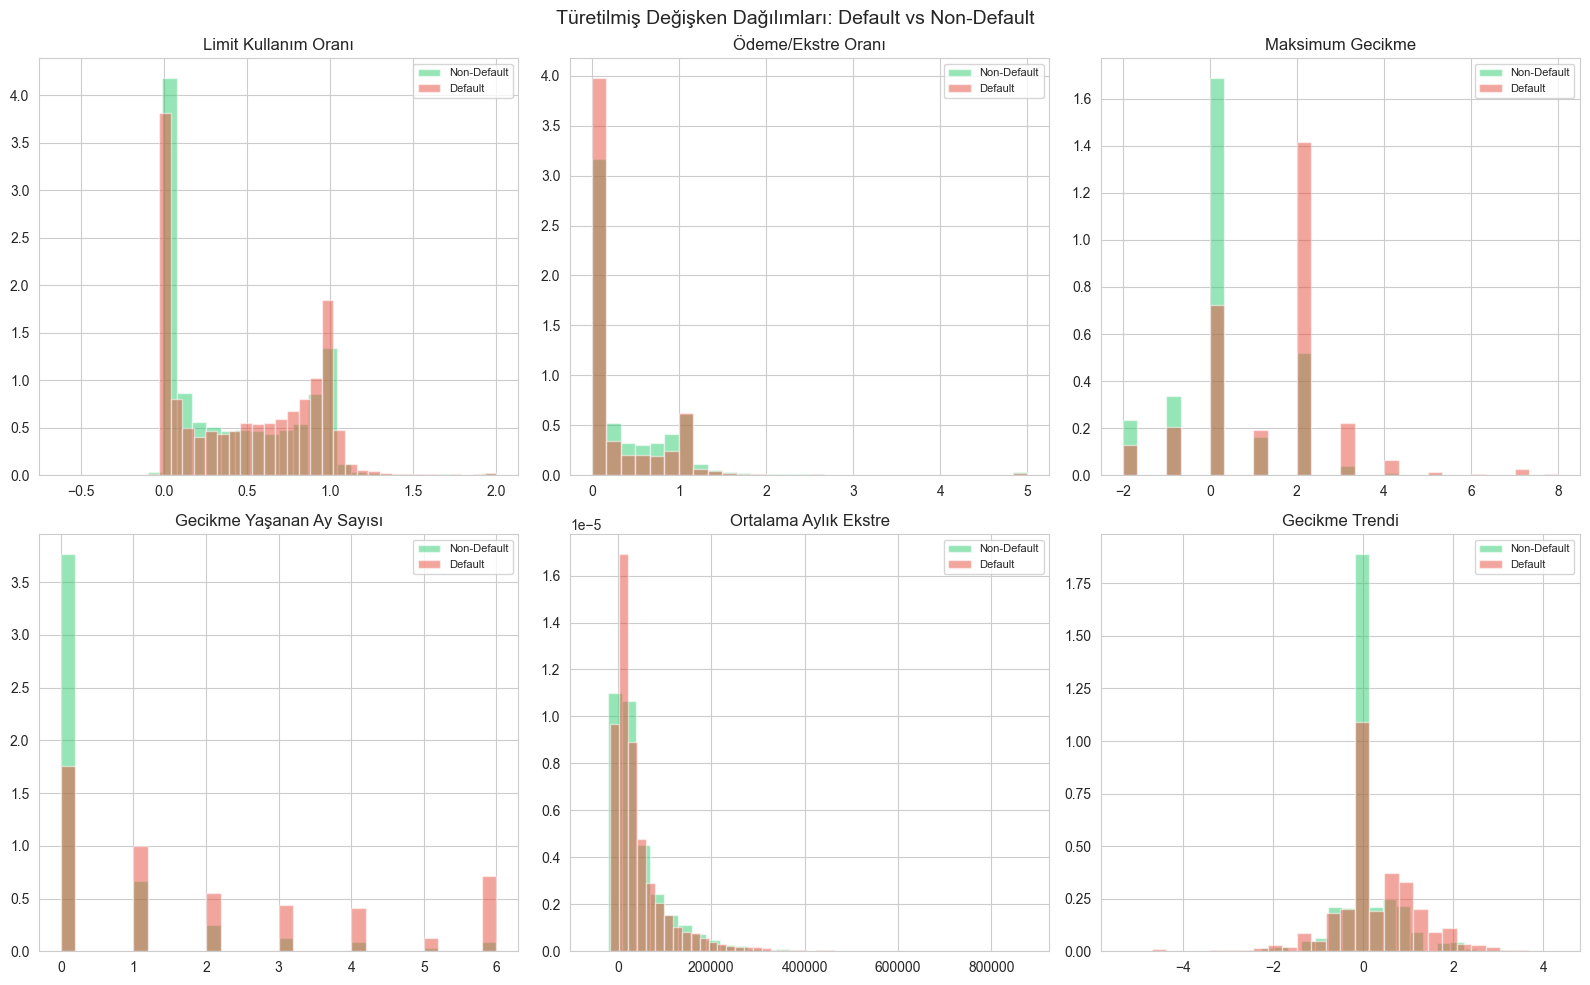

In [14]:
fig, axes = plt.subplots(2, 3, figsize=(16, 10))

plot_features = [
    ('UTIL_RATIO', 'Limit Kullanım Oranı'),
    ('PAY_TO_BILL_RATIO', 'Ödeme/Ekstre Oranı'),
    ('MAX_DELINQUENCY', 'Maksimum Gecikme'),
    ('DELINQUENCY_COUNT', 'Gecikme Yaşanan Ay Sayısı'),
    ('AVG_BILL', 'Ortalama Aylık Ekstre'),
    ('DELINQUENCY_TREND', 'Gecikme Trendi')
]

for idx, (feat, title) in enumerate(plot_features):
    ax = axes[idx // 3][idx % 3]
    for label, color in [(0, '#2ecc71'), (1, '#e74c3c')]:
        subset = df[df['DEFAULT_FLAG'] == label][feat]
        ax.hist(subset, bins=30, alpha=0.5, color=color, density=True,
                label='Default' if label == 1 else 'Non-Default')
    ax.set_title(title)
    ax.legend(fontsize=8)

plt.suptitle('Türetilmiş Değişken Dağılımları: Default vs Non-Default', fontsize=14)
plt.tight_layout()
plt.savefig('../reports/02_feature_distributions.png', dpi=150, bbox_inches='tight')
plt.show()

## 2.7 İşlenmiş Veriyi Kaydetme

In [15]:
# Modelleme için kullanılacak sütunları belirle
# Kategorik bandları encode etmeden kaydet (model notebook'unda yapılacak)
output_path = '../data/credit_features.csv'
df.to_csv(output_path)
print(f"İşlenmiş veri kaydedildi: {output_path}")
print(f"Shape: {df.shape}")
print(f"\nTüm sütunlar:")
for i, col in enumerate(df.columns, 1):
    print(f"  {i:>2}. {col}")

İşlenmiş veri kaydedildi: ../data/credit_features.csv
Shape: (30000, 42)

Tüm sütunlar:
   1. LIMIT_BAL
   2. SEX
   3. EDUCATION
   4. MARRIAGE
   5. AGE
   6. PAY_0
   7. PAY_2
   8. PAY_3
   9. PAY_4
  10. PAY_5
  11. PAY_6
  12. BILL_AMT1
  13. BILL_AMT2
  14. BILL_AMT3
  15. BILL_AMT4
  16. BILL_AMT5
  17. BILL_AMT6
  18. PAY_AMT1
  19. PAY_AMT2
  20. PAY_AMT3
  21. PAY_AMT4
  22. PAY_AMT5
  23. PAY_AMT6
  24. DEFAULT_FLAG
  25. MAX_DELINQUENCY
  26. AVG_DELINQUENCY
  27. DELINQUENCY_COUNT
  28. NEVER_DELINQUENT
  29. RECENT_DELINQUENT
  30. TOTAL_BILL
  31. TOTAL_PAY
  32. PAY_TO_BILL_RATIO
  33. RECENT_PAY_RATIO
  34. AVG_BILL
  35. AVG_PAY
  36. UTIL_RATIO
  37. AVG_UTIL_RATIO
  38. LIMIT_BAND
  39. AGE_BAND
  40. BILL_TREND
  41. PAY_TREND
  42. DELINQUENCY_TREND


## 2.8 Özet

### Yapılan İşlemler
1. **Hedef değişken** yeniden adlandırıldı (`DEFAULT_FLAG`)
2. **EDUCATION** ve **MARRIAGE** değişkenlerindeki belgelenmemiş değerler temizlendi
3. **16 yeni türetilmiş değişken** oluşturuldu:
   - Gecikme türevleri (5): MAX_DELINQUENCY, AVG_DELINQUENCY, DELINQUENCY_COUNT, NEVER_DELINQUENT, RECENT_DELINQUENT
   - Ekstre/Ödeme türevleri (6): TOTAL_BILL, TOTAL_PAY, PAY_TO_BILL_RATIO, RECENT_PAY_RATIO, AVG_BILL, AVG_PAY
   - Limit kullanım türevleri (2): UTIL_RATIO, AVG_UTIL_RATIO
   - Trend değişkenleri (3): BILL_TREND, PAY_TREND, DELINQUENCY_TREND

### Temel Bulgular
- **En güçlü sinyal:** Gecikme geçmişi değişkenleri (MAX_DELINQUENCY, DELINQUENCY_COUNT)
- **Pratik içgörü:** Hiç gecikme yaşamamış müşterilerin default oranı dramatik şekilde düşük
- **Limit kullanımı:** Yüksek utilization oranı default riski ile pozitif ilişkili

### Sonraki Adım
Model geliştirme notebook'unda bu değişkenler kullanılarak Logistic Regression (ana model) ve XGBoost (challenger model) kurulacak.